<a href="https://colab.research.google.com/github/Huii0529/Machine-Learning/blob/main/STQD6024_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Garment Employee Productivity Prediction: A Comparative Analysis of Regression Models Using Machine Learning**
**Fang Jia Hui, Sulayman bin Abdul Hadi, Venusha A/P Ravichandran | P170176**

Employee productivity is an important factor in the garment manufacturing industry as it directly affects production efficiency and overall operational performance. This project uses the Productivity Prediction of Garment Employees dataset obtained from the UCI Machine Learning Repository, which contains 1,197 observations of workforce and operational factors, including department, team, targeted productivity, overtime, incentives, idle time and number of workers. The main objective is to predict actual employee productivity based on these factors using regression techniques. Four regression methods are implemented and compared: Multiple Linear Regression, Mixed Forward–Backward Stepwise Regression, Ridge Regression and LASSO Regression. The dataset is first explored, visualised and preprocessed before model development. At least five-fold cross-validation is then performed to evaluate the models using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE) and Adjusted R-squared. Finally, the models are compared based on their predictive performance, selected variables, coefficient shrinkage and model complexity to identify the most suitable approach for predicting garment employee productivity.


**Dataset Source:** https://archive.ics.uci.edu/dataset/597/productivity+prediction+of+garment+employees

# **1.0 Data Understanding and Preprocessing**

## **1.1 Describing the prediction problem and variables**

The main objective of this project is to predict actual employee productivity, represented by the actual_productivity variable, which is a continuous numerical variable ranging from 0 to 1, with higher values indicating higher productivity. The dataset contains several independent variables related to garment production operations, including production factors such as Standard Minute Value (SMV), Work in Progress (WIP) and style changes; workforce factors such as department, team and number of workers; and management factors such as targeted productivity, overtime, financial incentives (BDT) and idle time. To understand the dataset and its suitability for regression modelling, the response variable and selected predictors are first explored through visualisations to examine their distributions and relationships. The dataset is then preprocessed by handling missing values, correcting data inconsistencies and converting categorical variables into numerical formats to ensure the data is suitable for subsequent regression model development.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Creating a file in google colab to house productivity data
import os
from google.colab import files

os.makedirs('data', exist_ok=True)

In [ ]:
# Testing data readability
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

garments = pd.read_csv("data/garments_worker_productivity.csv")
garments.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


## **1.2 Visualise Response and Selected Predictors**

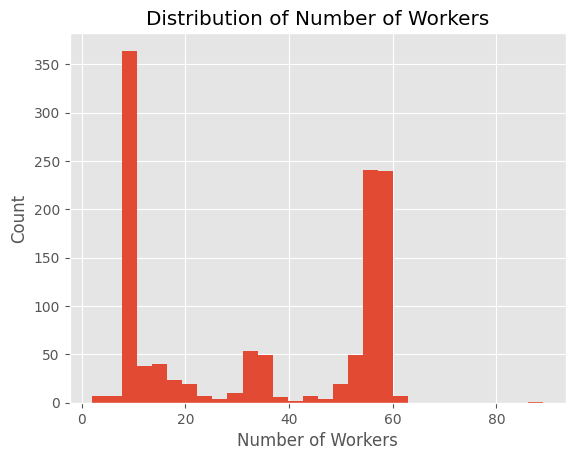

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")

plt.hist(garments['no_of_workers'], bins=30)
plt.title('Distribution of Number of Workers')
plt.xlabel('Number of Workers')
plt.ylabel('Count');

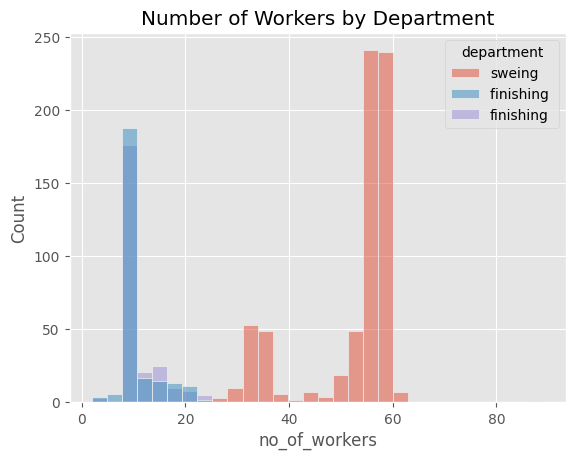

In [ ]:
sns.histplot(data=garments, x='no_of_workers', hue='department', bins=30)
plt.title('Number of Workers by Department');

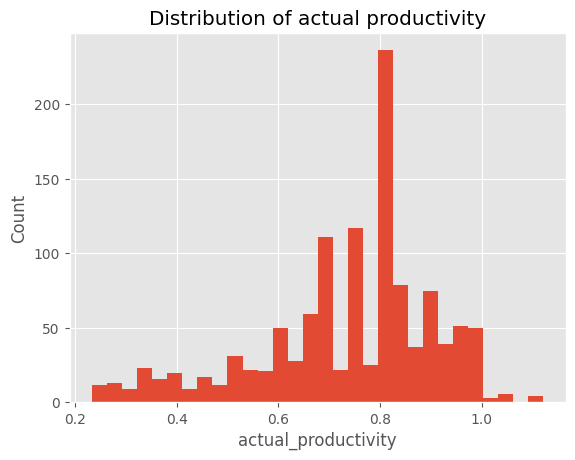

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")

plt.hist(garments['actual_productivity'], bins=30)
plt.title('Distribution of actual productivity')
plt.xlabel('actual_productivity')
plt.ylabel('Count');

In [ ]:
#Testing correlation between target and regressor variables

garments.select_dtypes('number').corr()['actual_productivity'].sort_values()

,actual_productivity
no_of_style_change,-0.207366
idle_men,-0.181734
team,-0.148753
smv,-0.122089
idle_time,-0.080851
no_of_workers,-0.057991
over_time,-0.054206
incentive,0.076538
wip,0.131147
targeted_productivity,0.421594


## **1.3 Preprocessing the data**

Several issues were detected during the preprocessing stage which required treatment. First, the 'wip' variable indicated 691 non-null out of 1197, which means 506 values are missing. fillna(0) will be used to address this.

Second, the department variable showed three unique values instead of two, because “finishing” was recorded both with and without a trailing space. The sewing department was also misspelt as “sweing”. str.strip() and replace() will be used to combine these into two clean levels, “sewing” and “finishing”.

Third, the quarter variable contained five levels, although a month is divided into only four quarters. The 44 observations labelled “Quarter5” cover days 29 to 31 of the month, so they will be merged into “Quarter4” using replace().

Fourth, the minimum value of targeted_productivity was 0.07, far below the 25th percentile of 0.70. This is likely a data entry error, and it will be corrected to 0.7.

Fifth, the incentive variable had a maximum of 3,600, well above its 75th percentile of 50. Further inspection showed that for the finishing department on 9 March 2015, the values of over_time and incentive had been swapped. These values will be switched back to their correct columns.

Sixth, wip contained extreme values of up to 23,122 against a median of 1,039, all recorded on 2 February 2015. These observations will be kept, as there is no clear evidence that they are errors, but their influence will be checked during modelling.

Seventh, team is stored as an integer but represents a team ID rather than a quantity. It will therefore be converted to a categorical variable using astype(str).

Eighth, the date variable will be dropped, as the aim is to predict productivity from team-level characteristics rather than to forecast over time.

Finally, idle_time, idle_men and no_of_style_change are zero for most observations. They will be retained, but they are expected to contribute little to the models.

In addition, actual_productivity has a maximum of 1.12, meaning some teams exceeded their target. These values are plausible and will be kept.

In [ ]:
garments.info()
display(garments.describe())
display(garments.describe(include=['object']))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
count,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858,0.735091
std,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687,0.174488
min,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705
25%,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307
50%,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333
75%,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253
max,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,89.000000,1.120437


,date,quarter,department,day
count,1197,1197,1197,1197
unique,59,5,3,6
top,1/31/2015,Quarter1,sweing,Wednesday
freq,24,360,691,208


In [ ]:
#Processing the data

import numpy as np
import pandas as pd

df = garments.copy()   # keep the original untouched

# 1. Missing wip -> 0                                        (extra: not in notes)
df['wip'] = df['wip'].fillna(0)

# 2. Department typos -> 'sewing' / 'finishing'               (extra: not in notes)
df['department'] = df['department'].str.strip().replace('sweing', 'sewing')

# 3. Quarter5 -> Quarter4                                     (notes: np.where + pd.Categorical, Week 1 College)
df['quarter'] = pd.Categorical(np.where(df['quarter'] == 'Quarter5', 'Quarter4', df['quarter']))

# 4. targeted_productivity typo 0.07 -> 0.7                   (extra: not in notes)
df.loc[df['targeted_productivity'] == 0.07, 'targeted_productivity'] = 0.7

# 5. Swap over_time and incentive back for 9 March 2015 finishing rows   (extra: not in notes)
mask = (df['date'] == '3/9/2015') & (df['department'] == 'finishing')
df.loc[mask, ['over_time', 'incentive']] = df.loc[mask, ['incentive', 'over_time']].values

# 6. Extreme wip values -> kept, nothing to do

# 7. team -> categorical                                       (extra: not in notes)
df['team'] = df['team'].astype(str)

# 8. Drop date                                                 (extra: not in notes)
df = df.drop(columns=['date'])

# 9-10. idle_time, idle_men, no_of_style_change and productivity > 1 -> kept, nothing to do

# Dummy variable for department                                (notes: Week 2 Credit, 'Female')
df['sewing'] = (df['department'] == 'sewing').astype(int)

# Check the result                                             (notes: info / describe, Week 1)
df.info()
display(df.describe())
display(df.describe(include=['object', 'category']))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   quarter                1197 non-null   category
 1   department             1197 non-null   object  
 2   day                    1197 non-null   object  
 3   team                   1197 non-null   object  
 4   targeted_productivity  1197 non-null   float64 
 5   smv                    1197 non-null   float64 
 6   wip                    1197 non-null   float64 
 7   over_time              1197 non-null   int64   
 8   incentive              1197 non-null   int64   
 9   idle_time              1197 non-null   float64 
 10  idle_men               1197 non-null   int64   
 11  no_of_style_change     1197 non-null   int64   
 12  no_of_workers          1197 non-null   float64 
 13  actual_productivity    1197 non-null   float64 
 14  sewing                 1197 non-null   i

,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,sewing
count,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,0.730159,15.062172,687.228070,4579.991646,25.679198,0.730159,0.369256,0.150376,34.609858,0.735091,0.577277
std,0.096017,10.943219,1514.582341,3335.480597,30.375119,12.709757,3.268987,0.427848,22.197687,0.174488,0.494199
min,0.350000,2.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705,0.000000
25%,0.700000,3.940000,0.000000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307,0.000000
50%,0.750000,15.260000,586.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333,1.000000
75%,0.800000,24.260000,1083.000000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253,1.000000
max,0.800000,54.560000,23122.000000,25920.000000,138.000000,300.000000,45.000000,2.000000,89.000000,1.120437,1.000000


,quarter,department,day,team
count,1197,1197,1197,1197
unique,4,2,6,12
top,Quarter1,sewing,Wednesday,8
freq,360,691,208,109


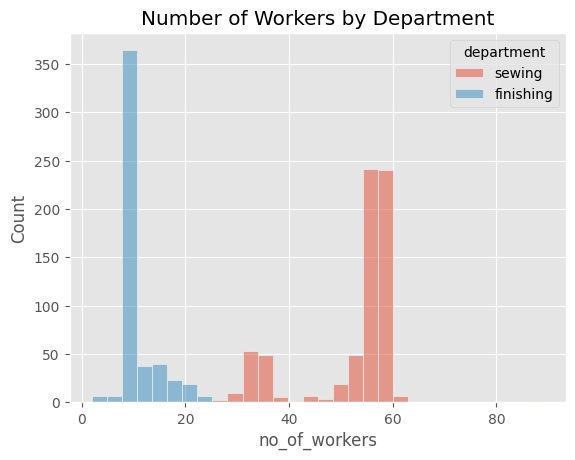

In [ ]:
#Test to observe there are only two departments with corrected names

sns.histplot(data=df, x='no_of_workers', hue='department', bins=30)
plt.title('Number of Workers by Department');

In [ ]:
#Splitting into training and testing datasets

obs_nums = np.arange(len(df))
np.random.seed(1)
np.random.shuffle(obs_nums)
top_70 = int(len(df) * .7)

train = df.iloc[obs_nums[:top_70]]
test  = df.iloc[obs_nums[top_70:]]

# **2.0 Regression Model Development**
## **2.1 Multiple Linear Regression Using All Predictors**

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

# Define X, y, and train/test splits from teammate's 'train' and 'test' DataFrames
y = df['actual_productivity']
X = df.drop(['actual_productivity', 'department'], axis=1)
X = pd.get_dummies(
    X, columns=['quarter', 'day', 'team'], drop_first=True, dtype=float
)

X_train, X_test = X.loc[train.index].copy(), X.loc[test.index].copy()
y_train, y_test = y.loc[train.index].copy(), y.loc[test.index].copy()
results = {}

# 1. Statsmodels OLS Summary
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())

# 2. Scikit-Learn LinearRegression
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred = mlr.predict(X_test)
results['MLR'] = mean_squared_error(y_test, y_pred)
print(f"\nTest MSE (70/30 split): {results['MLR']:.6f}")

# 3. 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=1)
rmse_scores, mae_scores, adj_r2_scores = [], [], []
p = X.shape[1]

for train_idx, val_idx in kf.split(X):
  X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
  y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

  fold_model = LinearRegression().fit(X_tr, y_tr)
  preds = fold_model.predict(X_val)

  n_val = len(y_val)
  r2 = r2_score(y_val, preds)
  adj_r2 = 1 - (1 - r2) * (n_val - 1) / (n_val - p - 1)

  rmse_scores.append(np.sqrt(mean_squared_error(y_val, preds)))
  mae_scores.append(mean_absolute_error(y_val, preds))
  adj_r2_scores.append(adj_r2)

print('\n=== 5-Fold Cross-Validation Results (Multiple Linear Regression) ===')
print(f'Average RMSE:        {np.mean(rmse_scores):.4f}')
print(f'Average MAE:         {np.mean(mae_scores):.4f}')
print(f'Average Adjusted R2: {np.mean(adj_r2_scores):.4f}')

                             OLS Regression Results                            
Dep. Variable:     actual_productivity   R-squared:                       0.389
Model:                             OLS   Adj. R-squared:                  0.367
Method:                  Least Squares   F-statistic:                     17.74
Date:                 Sun, 15 Nov 2026   Prob (F-statistic):           9.76e-68
Time:                         01:13:19   Log-Likelihood:                 479.61
No. Observations:                  837   AIC:                            -899.2
Df Residuals:                      807   BIC:                            -757.3
Df Model:                           29                                         
Covariance Type:             nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const               

A full Multiple Linear Regression (MLR) model was fitted using all 29 encoded predictors (retaining sewing as the binary department indicator and one-hot encoding quarter, day, and team with first-level drop) to establish an unpenalized baseline benchmark. Using 5-fold cross-validation (random_state=1), the full MLR model achieved an average RMSE of 0.1377, an average MAE of 0.0978, and an average Adjusted $R^2$ of 0.2881. On the 70/30 holdout test split, the model recorded a Test MSE of 0.022946 (Test RMSE = 0.1515), compared to a training $R^2$ of 0.453 (training Adjusted $R^2$ = 0.433, $F(29, 807) = 23.01, p < 0.001$).   

The notable drop from the training Adjusted $R^2$ (0.433) to the 5-fold cross-validated Adjusted $R^2$ (0.2881) indicates moderate overfitting. Because full MLR retains all 29 predictors without penalty, the degrees-of-freedom adjustment ($n - p - 1$) heavily penalizes the inclusion of non-informative variables.   

Out of the 29 predictors, 18 variables are statistically insignificant at the $\alpha = 0.05$ level, including all quarter indicators ($p \ge 0.113$), all day of the week indicators ($p \ge 0.105$), wip ($p = 0.677$), over_time ($p = 0.109$), idle_time ($p = 0.648$), no_of_style_change ($p = 0.382$), and half of the team dummies (team_2 through team_5, team_7, team_12). Keeping these noisy variables inflates model variance without improving out-of-sample predictive accuracy.   

Positive drivers: targeted_productivity ($\beta = +0.5331, p < 0.001$), financial incentive ($\beta = +0.0031, p < 0.001$), and no_of_workers ($\beta = +0.0029, p = 0.003$) have strong, statistically significant positive effects on actual productivity.

Negative drivers: Operating in the sewing department ($\beta = -0.1587, p < 0.001$, indicating ~15.9 percentage points lower productivity than finishing teams on average), higher task complexity (smv, $\beta = -0.0055, p < 0.001$), worker stoppages (idle_men, $\beta = -0.0064, p < 0.001$), and specific underperforming teams (team_6, team_8, team_9, team_10, team_11, all $p < 0.05$ relative to team_1) significantly reduce productivity.

The OLS diagnostic report flags a high condition number ($9.32 \times 10^4$), indicating strong multicollinearity and unscaled feature disparities (e.g., sewing, smv, and no_of_workers are structurally correlated across departments). This instability motivates feature selection (Mixed Stepwise) and coefficient shrinkage (Ridge/LASSO).

While full MLR provides clear coefficient interpretability and baseline significance testing, retaining 18 insignificant predictors degrades out-of-sample Adjusted $R^2$ (0.2881) and introduces multicollinearity. (Once your teammates plug in their 5-fold CV RMSE, MAE, and Adjusted $R^2$, compare them directly here—typically LASSO or Mixed Stepwise will be recommended if they achieve comparable or lower RMSE/MAE with far fewer predictors, or Ridge if it yields the lowest CV error by stabilizing correlated features).

Management should prioritize setting realistic targeted_productivity benchmarks paired with structured incentive schemes (the two strongest positive drivers), minimize idle_men stoppages, and provide targeted process support to the sewing department and lagging teams (team_6, team_8–team_11) when handling high-SMV garments.

OLS assumes linear relationships and normally distributed errors, whereas the diagnostic Jarque-Bera test ($JB = 193.23, p < 0.001$) shows skewed, heavy-tailed residuals—likely because actual_productivity is bounded near 0 and 1.   

Imputing 506 missing wip values as 0 and retaining extreme spikes (up to 23,122) may distort linear slope estimates.   

Dropping date treats daily team observations as independent, ignoring potential time-series autocorrelation across consecutive production days.

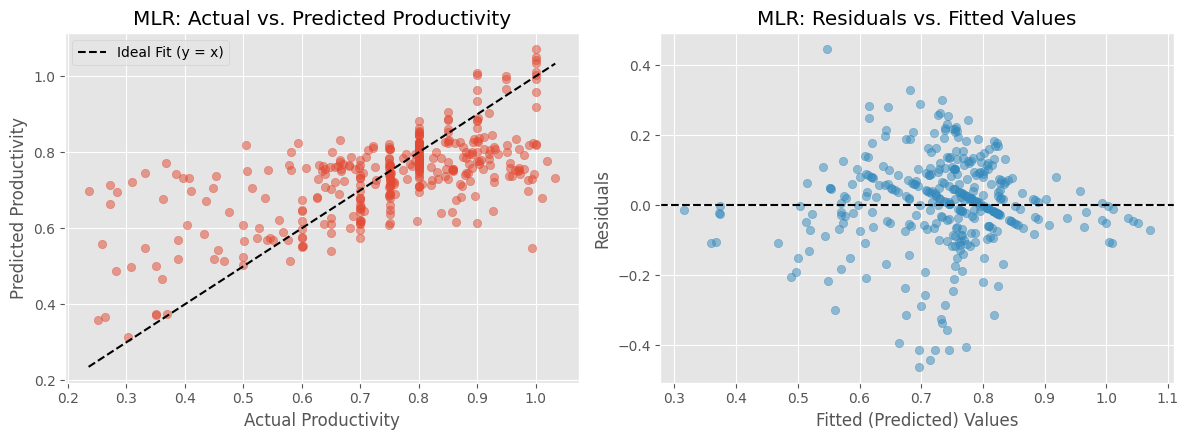

In [ ]:
import matplotlib.pyplot as plt

plt.style.use('ggplot')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Actual vs. Predicted Productivity
axes[0].scatter(y_test, y_pred, alpha=0.5, color='#E24A33')
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'k--',
    lw=1.5,
    label='Ideal Fit (y = x)',
)
axes[0].set_title('MLR: Actual vs. Predicted Productivity')
axes[0].set_xlabel('Actual Productivity')
axes[0].set_ylabel('Predicted Productivity')
axes[0].legend()

# Plot 2: Residuals vs. Fitted Values
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.5, color='#348ABD')
axes[1].axhline(0, color='k', linestyle='--', lw=1.5)
axes[1].set_title('MLR: Residuals vs. Fitted Values')
axes[1].set_xlabel('Fitted (Predicted) Values')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

Actual vs. Predicted (Left): While the model follows the upward diagonal trend around the $0.65\text{–}0.85$ productivity range, it severely over-predicts low-productivity days (when actual productivity drops to $0.25\text{–}0.45$, the model still predicts $\sim 0.50\text{–}0.80$).

Residuals vs. Fitted (Right): The residuals are not randomly scattered around zero, there is a sharp diagonal upper boundary (due to actual_productivity clustering near $0.80\text{–}1.00$) alongside large negative residuals down to $-0.50$, visually confirming heteroscedasticity and non-linear behavior in the data.

## **2.2 Mixed Forward–backward Stepwise Regression**

Mixed Forward–Backward Stepwise Regression was applied to identify the most relevant independent variables for predicting actual productivity.

The selection process used the following criteria:

* Entry threshold: 0.05. A predictor was added when its p-value was **below 0.05**.

* Removal threshold: 0.10. A selected predictor was removed when its p-value **exceeded 0.10**.

* Selection procedure: The model started with no predictors. In the forward step, the remaining predictor with the lowest p-value was added if it met the entry threshold. After each addition, the backward step checked the selected predictors and removed the predictor with the highest p-value if it exceeded the removal threshold.

* Stopping rule: The process stopped when no remaining predictor met the entry threshold and all selected predictors met the removal criterion.

This combined approach allows the model to add relevant predictors and reconsider previously selected predictors throughout the selection process.

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [ ]:
# Separate predictors and response variable

X = df.drop(columns=['actual_productivity', 'department'])
X = pd.get_dummies(X, drop_first=True, dtype=int)

y = df['actual_productivity']

# Create training and testing datasets

X_train = X.loc[train.index].copy()
X_test = X.loc[test.index].copy()

y_train = y.loc[train.index].copy()
y_test = y.loc[test.index].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Number of predictors:", X_train.shape[1])

Training observations: 837
Testing observations: 360
Number of predictors: 29


In [ ]:
def stepwise_selection(X, y, entry_threshold=0.05,
                       removal_threshold=0.10):

    selected_features = []

    while True:

        # Forward Selection
        remaining_features = [
            feature for feature in X.columns
            if feature not in selected_features
        ]

        best_feature = None
        best_p_value = 1

        for feature in remaining_features:

            features = selected_features + [feature]

            X_model = sm.add_constant(X[features], has_constant='add')
            model = sm.OLS(y, X_model).fit()

            p_value = model.pvalues[feature]

            if pd.notna(p_value) and p_value < best_p_value:
                best_p_value = p_value
                best_feature = feature

        forward_changed = False

        if best_feature is not None and best_p_value < entry_threshold:

            selected_features.append(best_feature)
            forward_changed = True

        # Backward Elimination
        backward_changed = False

        while len(selected_features) > 0:

            X_model = sm.add_constant(
                X[selected_features],
                has_constant='add'
            )

            model = sm.OLS(y, X_model).fit()

            p_values = model.pvalues.drop('const')

            worst_feature = p_values.idxmax()
            worst_p_value = p_values.max()

            if worst_p_value > removal_threshold:

                selected_features.remove(worst_feature)
                backward_changed = True

            else:
                break

        # Stopping Rule
        if not forward_changed and not backward_changed:
            break

    return selected_features

In [ ]:
# Set up 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

cv_results = []
selected_features_by_fold = []

# Perform cross-validation
for fold, (train_index, val_index) in enumerate(
    kf.split(X_train), 1
):

    # Split training data into fold-training and validation data
    X_fold_train = X_train.iloc[train_index]
    X_fold_val = X_train.iloc[val_index]

    y_fold_train = y_train.iloc[train_index]
    y_fold_val = y_train.iloc[val_index]

    # Perform stepwise variable selection
    selected = stepwise_selection(
        X_fold_train,
        y_fold_train,
        entry_threshold=0.05,
        removal_threshold=0.10
    )

    selected_features_by_fold.append(selected)

    # Fit OLS model using selected predictors
    X_model_train = sm.add_constant(
        X_fold_train[selected],
        has_constant='add'
    )

    X_model_val = sm.add_constant(
        X_fold_val[selected],
        has_constant='add'
    )

    model = sm.OLS(y_fold_train, X_model_train).fit()

    # Predict validation data
    predictions = model.predict(X_model_val)

    # Calculate evaluation metrics
    rmse = np.sqrt(
        mean_squared_error(y_fold_val, predictions)
    )

    mae = mean_absolute_error(y_fold_val, predictions)

    r2 = r2_score(y_fold_val, predictions)

    # Calculate validation Adjusted R-squared
    n = len(y_fold_val)
    p = len(selected)

    if n > p + 1:
        adj_r2 = 1 - (
            (1 - r2) * (n - 1) / (n - p - 1)
        )
    else:
        adj_r2 = np.nan

    cv_results.append({
        'Fold': fold,
        'Selected Predictors': p,
        'RMSE': rmse,
        'MAE': mae,
        'Adjusted R2': adj_r2
    })


# Display results for each fold
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Fold,Selected Predictors,RMSE,MAE,Adjusted R2
0,1,10,0.1486,0.1044,0.2546
1,2,6,0.1395,0.1015,0.3447
2,3,4,0.1552,0.1047,0.3092
3,4,6,0.1363,0.0949,0.3335
4,5,10,0.1258,0.0901,0.3285


The results show that the number of selected predictors ranged from four to ten. This indicates that the selection process identified different predictor combinations depending on the observations included in each training fold.

The variation suggests that the selected predictors may be somewhat sensitive to changes in the training data.

Among the five folds, Fold 3 recorded the highest RMSE of 0.1552, indicating the largest prediction error based on RMSE. In contrast, Fold 5 achieved the lowest RMSE of 0.1258 and the lowest MAE of 0.0901, indicating the smallest prediction errors among the five validation folds.

Fold 2 achieved the highest adjusted R² of 0.3447, while Fold 1 recorded the lowest adjusted R² of 0.2546.

These differences indicate that the model's predictive performance varied depending on the training and validation observations used in each fold.

In [ ]:
cv_summary = pd.DataFrame({
    'Metric': ['RMSE', 'MAE', 'Adjusted R2'],

    'Mean': [
        cv_results_df['RMSE'].mean(),
        cv_results_df['MAE'].mean(),
        cv_results_df['Adjusted R2'].mean()
    ],

    'Standard Deviation': [
        cv_results_df['RMSE'].std(),
        cv_results_df['MAE'].std(),
        cv_results_df['Adjusted R2'].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,RMSE,0.1411,0.0114
1,MAE,0.0991,0.0064
2,Adjusted R2,0.3141,0.0357


The average RMSE was 0.1411, while the average MAE was 0.0991. These values indicate the model's average prediction errors across the five validation folds.

The average adjusted R² was 0.3141, indicating that the model explained approximately 31.41% of the variation in actual productivity across the validation folds, after adjusting for the number of selected predictors.

The standard deviations of RMSE and MAE were relatively small, at 0.0114 and 0.0064 respectively. This suggests that the prediction errors did not vary substantially across the five folds.

However, the adjusted R² standard deviation was 0.0357, indicating some variation in the model's explanatory performance across the folds.

Overall, the cross-validation results indicate moderate predictive performance, with some variation in the predictors selected and the explanatory power of the model across different data subsets.

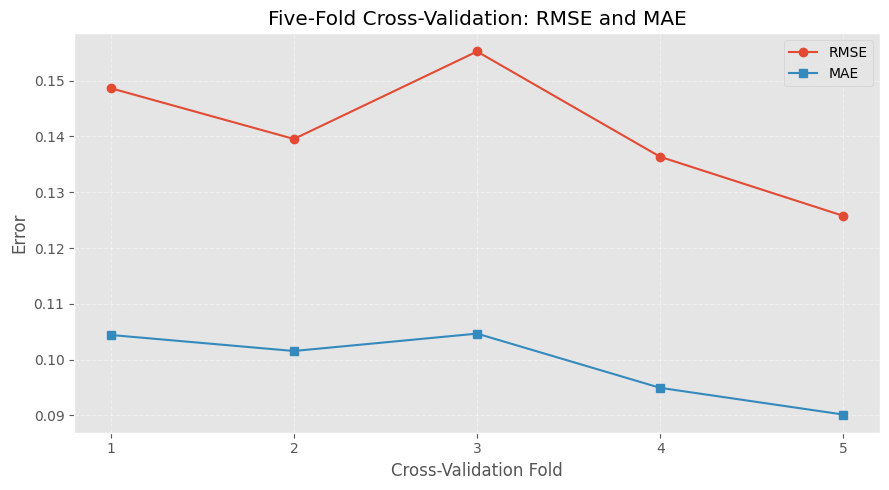

In [ ]:
# Use the cross-validation results DataFrame
plt.figure(figsize=(9, 5))

folds = cv_results_df['Fold']

plt.plot(
    folds,
    cv_results_df['RMSE'],
    marker='o',
    label='RMSE'
)

plt.plot(
    folds,
    cv_results_df['MAE'],
    marker='s',
    label='MAE'
)

plt.xlabel('Cross-Validation Fold')
plt.ylabel('Error')
plt.title('Five-Fold Cross-Validation: RMSE and MAE')
plt.xticks(folds)
plt.legend()
plt.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

The five-fold cross-validation performance plot compares the RMSE and MAE values obtained from each validation fold. Fold 3 recorded the highest RMSE of 0.1552, while Fold 5 achieved the lowest RMSE of 0.1258 and the lowest MAE of 0.0901. The average RMSE and MAE across the five folds were 0.1411 and 0.0991, respectively. The relatively small standard deviations of 0.0114 for RMSE and 0.0064 for MAE suggest that the model's prediction errors were reasonably consistent across the validation folds.

In [ ]:
# Final variable selection using the full training dataset
selected_features = stepwise_selection(
    X_train,
    y_train,
    entry_threshold=0.05,
    removal_threshold=0.10
)

print("Final Selected Variables:", selected_features)
print("Total Selected Variables:", len(selected_features))

Final Selected Variables: ['targeted_productivity', 'incentive', 'sewing', 'team_4', 'team_3', 'idle_men', 'smv', 'no_of_workers', 'team_11', 'over_time']
Total Selected Variables: 10


In [ ]:
# Prepare final training and testing predictors
X_train_final = sm.add_constant(
    X_train[selected_features],
    has_constant='add'
)

X_test_final = sm.add_constant(
    X_test[selected_features],
    has_constant='add'
)

# Fit final OLS model
final_model = sm.OLS(y_train, X_train_final).fit()

# Display regression results
print(final_model.summary())

                             OLS Regression Results                            
Dep. Variable:     actual_productivity   R-squared:                       0.376
Model:                             OLS   Adj. R-squared:                  0.369
Method:                  Least Squares   F-statistic:                     49.79
Date:                 Sun, 15 Nov 2026   Prob (F-statistic):           6.12e-78
Time:                         01:14:39   Log-Likelihood:                 470.65
No. Observations:                  837   AIC:                            -919.3
Df Residuals:                      826   BIC:                            -867.3
Df Model:                           10                                         
Covariance Type:             nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const               

The model achieved an R-squared of 0.376, indicating that the 10 selected predictors explained approximately 37.6% of the variation in actual productivity in the training dataset.

The adjusted R-squared was 0.369, indicating that the model explained approximately 36.9% of the variation after accounting for the number of predictors included.

The F-statistic was 49.79, with a p-value of 6.12 × 10⁻⁷⁸. Since this p-value was below 0.05, the overall regression model was statistically significant. This suggests that the selected predictors collectively had a statistically significant relationship with actual productivity.

In [ ]:
# Generate predictions
train_pred = final_model.predict(X_train_final)
test_pred = final_model.predict(X_test_final)

# Calculate final testing metrics
test_r2 = r2_score(y_test, test_pred)

n = len(y_test)
p = len(selected_features)

test_adj_r2 = 1 - (
    (1 - test_r2) * (n - 1) / (n - p - 1)
)

evaluation = pd.DataFrame({
    'Metric': [
        'Training R2',
        'Training Adjusted R2',
        'Testing R2',
        'Testing Adjusted R2',
        'Testing MAE',
        'Testing RMSE'
    ],

    'Value': [
        final_model.rsquared,
        final_model.rsquared_adj,
        test_r2,
        test_adj_r2,
        mean_absolute_error(y_test, test_pred),
        np.sqrt(mean_squared_error(y_test, test_pred))
    ]
})

display(evaluation.round(4))

,Metric,Value
0,Training R2,0.3761
1,Training Adjusted R2,0.3685
2,Testing R2,0.4105
3,Testing Adjusted R2,0.3936
4,Testing MAE,0.0954
5,Testing RMSE,0.1332


The testing R² was **0.4105**, indicating that the model explained approximately 41.05% of the variation in actual productivity in the testing dataset.

The testing MAE was **0.0954**, meaning that the average absolute difference between the predicted and actual productivity values was approximately 0.0954.

The testing RMSE was **0.1332**, indicating the prediction error while giving greater weight to larger errors.

Interestingly, the testing R² of 0.4105 was **slightly higher** than the training R² of 0.3761. This can occur because the training and testing datasets contain different observations and may have different data distributions. It does not necessarily mean that the model performs better on all unseen data.

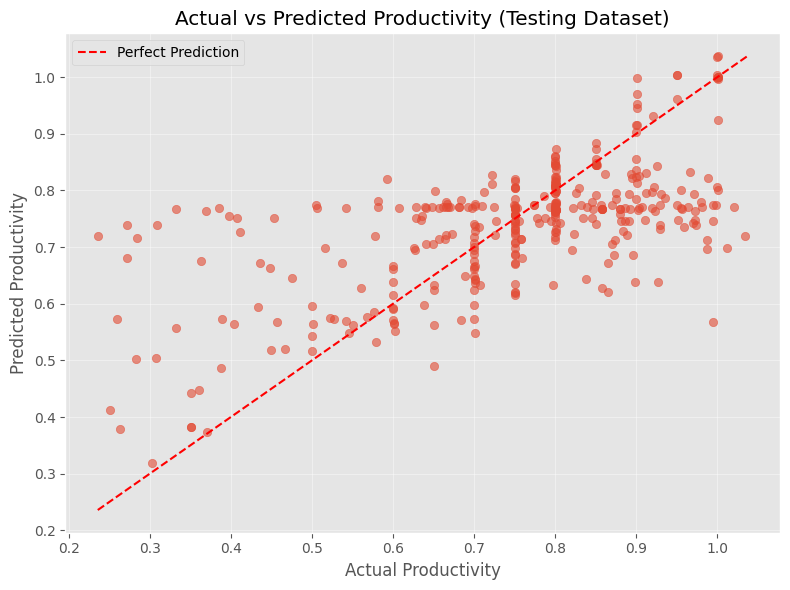

In [ ]:
from sklearn.metrics import r2_score

# Generate predictions using the testing dataset
test_pred = final_model.predict(X_test_final)

# Create scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(y_test, test_pred, alpha=0.6)

# Perfect prediction reference line
min_value = min(y_test.min(), test_pred.min())
max_value = max(y_test.max(), test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Productivity')
plt.ylabel('Predicted Productivity')
plt.title('Actual vs Predicted Productivity (Testing Dataset)')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

The actual versus predicted productivity plot evaluates the predictive performance of the final OLS regression model using the 30% testing dataset. The horizontal axis represents the actual productivity values, while the vertical axis represents the predicted productivity values. The red dashed line represents perfect predictions, where the predicted values are equal to the actual values. Data points located closer to this line indicate more accurate predictions, whereas points further away indicate larger prediction errors. Based on the testing results, the model achieved an R-squared of 0.4105, an MAE of 0.0954 and an RMSE of 0.1332. This indicates that the model demonstrates moderate predictive performance, although some differences between actual and predicted productivity remain.

Overall, the mixed forward–backward stepwise regression model **achieved moderate predictive performance**. The five-fold cross-validation results and final testing evaluation demonstrate that the model was able to identify relevant predictors and produce predictions on data that were not used during model fitting.

## **2.3 Ridge and Lasso Regressions**

Our full MLR model in Section 2.1 had a few limitations. Many of its 29 predictors were not useful (18 were statistically insignificant), several predictors were closely related to each other, and the model performed noticeably worse on new data than on the data it was trained on. This means the model was fitting some noise rather than just the real patterns.

Ridge and LASSO regression are designed to deal with these problems. Both work like ordinary linear regression, but with one extra rule which is penalising models for having large coefficients. This pushes the model to keep its coefficients small, so that no single predictor has an exaggerated effect and the model is less likely to fit noise.

The two methods differ in one important way:

- **Ridge** shrinks all coefficients towards zero but keeps every predictor in the model.
- **LASSO** can shrink some coefficients all the way to zero, which removes those predictors from the model entirely. This makes it useful for finding which variables actually matter.

How strong the penalty is depends on a setting called **alpha**. An alpha of zero means no penalty at all (the same as ordinary linear regression), while a very large alpha shrinks everything towards zero. We used cross-validation to find the alpha that gives the best predictions.

Before fitting, all predictors were put on the same scale, so that variables with large numbers (such as overtime minutes) are not treated differently from variables with small numbers (such as 0/1 indicators). We also used the same training and testing split as the previous models so that all results can be compared fairly.

### **2.3.1 Ridge Regressions**

In [ ]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.metrics import mean_squared_error

y = df.actual_productivity
X = df.drop(['actual_productivity', 'department'], axis=1)     # 'sewing' replaces department
X = pd.get_dummies(X, columns=['quarter', 'day', 'team'], drop_first=True, dtype=float)

X.info()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
results = {}     # store each model's test MSE here

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   targeted_productivity  1197 non-null   float64
 1   smv                    1197 non-null   float64
 2   wip                    1197 non-null   float64
 3   over_time              1197 non-null   int64  
 4   incentive              1197 non-null   int64  
 5   idle_time              1197 non-null   float64
 6   idle_men               1197 non-null   int64  
 7   no_of_style_change     1197 non-null   int64  
 8   no_of_workers          1197 non-null   float64
 9   sewing                 1197 non-null   int64  
 10  quarter_Quarter2       1197 non-null   float64
 11  quarter_Quarter3       1197 non-null   float64
 12  quarter_Quarter4       1197 non-null   float64
 13  day_Saturday           1197 non-null   float64
 14  day_Sunday             1197 non-null   float64
 15  day_

First, the response variable (actual productivity) and predictors were defined. The department column was dropped because the sewing indicator already captures it. The categorical variables quarter, day and team were converted into 0/1 dummy variables, with the first category of each used as the baseline. This gives 29 predictors in total.

In [ ]:
#Generate an array of alpha values
alphas = 10**np.linspace(10, -2, 100) * 0.5
alphas


array([5.00000000e+09, 3.78231664e+09, 2.86118383e+09, 2.16438064e+09,
       1.63727458e+09, 1.23853818e+09, 9.36908711e+08, 7.08737081e+08,
       5.36133611e+08, 4.05565415e+08, 3.06795364e+08, 2.32079442e+08,
       1.75559587e+08, 1.32804389e+08, 1.00461650e+08, 7.59955541e+07,
       5.74878498e+07, 4.34874501e+07, 3.28966612e+07, 2.48851178e+07,
       1.88246790e+07, 1.42401793e+07, 1.07721735e+07, 8.14875417e+06,
       6.16423370e+06, 4.66301673e+06, 3.52740116e+06, 2.66834962e+06,
       2.01850863e+06, 1.52692775e+06, 1.15506485e+06, 8.73764200e+05,
       6.60970574e+05, 5.00000000e+05, 3.78231664e+05, 2.86118383e+05,
       2.16438064e+05, 1.63727458e+05, 1.23853818e+05, 9.36908711e+04,
       7.08737081e+04, 5.36133611e+04, 4.05565415e+04, 3.06795364e+04,
       2.32079442e+04, 1.75559587e+04, 1.32804389e+04, 1.00461650e+04,
       7.59955541e+03, 5.74878498e+03, 4.34874501e+03, 3.28966612e+03,
       2.48851178e+03, 1.88246790e+03, 1.42401793e+03, 1.07721735e+03,
      

A range of 100 alpha values was created, from very large to very small. Ridge and LASSO are fitted at each value to show how the coefficients shrink as the penalty increases, and cross-validation is later used to choose the best alpha from this range.

In [ ]:
ridge = Ridge()
coefs = []

# Scaling data for ridge and lasso

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for a in alphas:
    ridge.set_params(alpha=a)
    ridge.fit(X_scaled, y)
    coefs.append(ridge.coef_)

np.shape(coefs)

(100, 29)

All predictors were standardised to the same scale, so that the penalty treats them fairly regardless of their original units. Ridge regression was then fitted once for each of the 100 alpha values, and the 29 coefficients from each fit were saved. These are plotted below to show how the coefficients shrink as alpha increases.

Text(0, 0.5, 'weights')

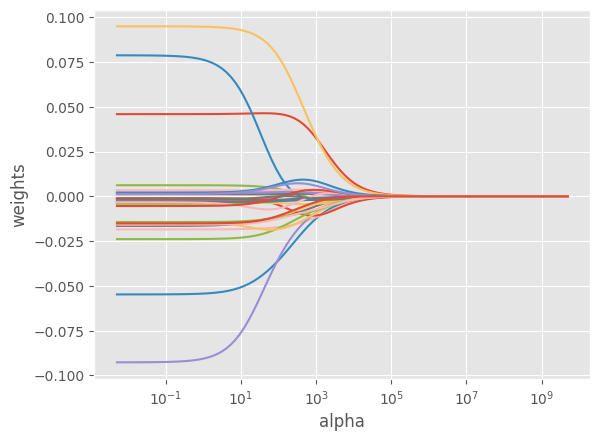

In [ ]:
ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')
plt.axis('tight')
plt.xlabel('alpha')
plt.ylabel('weights')

The plot shows how each of the 29 ridge coefficients changes as alpha increases. At small alpha values, the coefficients are close to those of ordinary linear regression, with incentive, no_of_workers and targeted_productivity having the largest positive effects and sewing and smv the largest negative effects. As alpha increases, all coefficients shrink towards zero. Sewing and no_of_workers shrink the fastest because they are strongly correlated, which is the kind of instability ridge regression is designed to reduce. At very large alpha values, all coefficients are effectively zero and the model predicts only the mean. Ridge shrinks coefficients gradually but never sets them exactly to zero.


In [ ]:
# Reusing the same test and train splits
X_train = scaler.fit_transform(X.loc[train.index])
X_test  = scaler.transform(X.loc[test.index])
y_train = y.loc[train.index]
y_test  = y.loc[test.index]

In [ ]:
ridge2 = Ridge(alpha = 4)
ridge2.fit(X_train, y_train)             # Fit a ridge regression on the training data
pred2 = ridge2.predict(X_test)           # Use this model to predict the test data
print(pd.Series(ridge2.coef_, index = X.columns)) # Print coefficients
print(mean_squared_error(y_test, pred2))          # Calculate the test MSE

targeted_productivity    0.045768
smv                     -0.049498
wip                     -0.001269
over_time               -0.019040
incentive                0.092093
idle_time                0.006605
idle_men                -0.017221
no_of_style_change      -0.003359
no_of_workers            0.060015
sewing                  -0.071428
quarter_Quarter2         0.001906
quarter_Quarter3        -0.000236
quarter_Quarter4        -0.002568
day_Saturday             0.002531
day_Sunday              -0.000147
day_Thursday             0.001142
day_Tuesday              0.001553
day_Wednesday           -0.001973
team_10                 -0.018011
team_11                 -0.026874
team_12                 -0.011423
team_2                  -0.008511
team_3                   0.001615
team_4                   0.001915
team_5                  -0.008658
team_6                  -0.018510
team_7                  -0.015801
team_8                  -0.018684
team_9                  -0.016054
dtype: float64

In [ ]:
## Let alpha=10^10
ridge3 = Ridge(alpha = 10**10)
ridge3.fit(X_train, y_train)             # Fit a ridge regression on the training data
pred3 = ridge3.predict(X_test)           # Use this model to predict the test data
print(pd.Series(ridge3.coef_, index = X.columns)) # Print coefficients
print(mean_squared_error(y_test, pred3))          # Calculate the test MSE

targeted_productivity    5.997416e-09
smv                     -1.429075e-09
wip                      7.306054e-10
over_time               -6.100761e-10
incentive                4.710799e-09
idle_time               -9.977728e-10
idle_men                -2.252420e-09
no_of_style_change      -2.842550e-09
no_of_workers           -5.689148e-10
sewing                  -1.001709e-09
quarter_Quarter2         9.054634e-11
quarter_Quarter3        -1.022314e-09
quarter_Quarter4        -4.228078e-10
day_Saturday             3.736581e-10
day_Sunday               1.352466e-10
day_Thursday            -3.260368e-10
day_Tuesday             -2.816664e-11
day_Wednesday           -3.439779e-11
team_10                 -5.731786e-10
team_11                 -1.266895e-09
team_12                  7.239905e-10
team_2                   7.786574e-10
team_3                   1.787670e-09
team_4                   1.049114e-09
team_5                  -1.073490e-09
team_6                  -9.192691e-10
team_7      

In [ ]:
### The least squares, alpha = 0
ridge2 = Ridge(alpha = 0)
ridge2.fit(X_train, y_train)             # Fit a ridge regression on the training data
pred = ridge2.predict(X_test)            # Use this model to predict the test data
print(pd.Series(ridge2.coef_, index = X.columns)) # Print coefficients
print(mean_squared_error(y_test, pred))           # Calculate the test MSE

targeted_productivity    0.045709
smv                     -0.051925
wip                     -0.001337
over_time               -0.019898
incentive                0.093001
idle_time                0.006749
idle_men                -0.017404
no_of_style_change      -0.003250
no_of_workers            0.071090
sewing                  -0.080164
quarter_Quarter2         0.002009
quarter_Quarter3        -0.000189
quarter_Quarter4        -0.002619
day_Saturday             0.002629
day_Sunday              -0.000100
day_Thursday             0.001229
day_Tuesday              0.001652
day_Wednesday           -0.002067
team_10                 -0.018435
team_11                 -0.027631
team_12                 -0.010595
team_2                  -0.009048
team_3                   0.000997
team_4                   0.001306
team_5                  -0.008991
team_6                  -0.017565
team_7                  -0.016185
team_8                  -0.019129
team_9                  -0.016525
dtype: float64

Before letting cross-validation choose alpha, ridge regression was fitted with three hand-picked alpha values to show how the penalty affects the model:

- **α = 0:** no penalty at all, which gives the same result as ordinary linear regression. This acts as a baseline for comparison.
- **α = 4:** a moderate penalty, which shrinks the coefficients slightly.
- **α = 10¹⁰:** an extremely large penalty, which shrinks every coefficient to almost zero.

Each model was trained on the training data and evaluated on the test data. Comparing them shows the trade-off that alpha controls: too little penalty may let the model fit noise in the training data, while too much penalty removes useful information, so the model underfits. The best alpha lies somewhere in between, which is why cross-validation is used next to find it.

In [ ]:
###  use cross-validation to choose the tuning parameter alpha.
ridgecv = RidgeCV(alphas = alphas, scoring = 'neg_mean_squared_error')
ridgecv.fit(X_train, y_train)
ridgecv.alpha_

np.float64(7.087370814634009)

In [ ]:
###Fit to the test data
ridge4 = Ridge(alpha = ridgecv.alpha_)
ridge4.fit(X_train, y_train)
mean_squared_error(y_test, ridge4.predict(X_test))

0.017378586187752246

In [ ]:
### Ridge coefficients (trained on training data with best alpha)
print(pd.Series(ridge4.coef_, index = X.columns))

targeted_productivity    0.045799
smv                     -0.047925
wip                     -0.001205
over_time               -0.018504
incentive                0.091379
idle_time                0.006492
idle_men                -0.017098
no_of_style_change      -0.003471
no_of_workers            0.053339
sewing                  -0.066136
quarter_Quarter2         0.001841
quarter_Quarter3        -0.000278
quarter_Quarter4        -0.002532
day_Saturday             0.002480
day_Sunday              -0.000174
day_Thursday             0.001091
day_Tuesday              0.001495
day_Wednesday           -0.001906
team_10                 -0.017684
team_11                 -0.026329
team_12                 -0.011834
team_2                  -0.008116
team_3                   0.002051
team_4                   0.002336
team_5                  -0.008415
team_6                  -0.018997
team_7                  -0.015519
team_8                  -0.018345
team_9                  -0.015702
dtype: float64

Instead of guessing alpha, cross-validation was used to choose it automatically. RidgeCV tried all 100 alpha values on the training data and selected **α ≈ 7.09**, which is a fairly light penalty. This means the model only needed a small amount of shrinkage.

Ridge regression was then fitted on the training data using this alpha and evaluated on the test data. The **test MSE was 0.01738 (RMSE ≈ 0.1318)**. This is almost identical to ordinary linear regression (α = 0, test MSE = 0.01730), so shrinking the coefficients did not noticeably improve prediction accuracy on this dataset.

Because all predictors were standardised, the size of each coefficient shows how strongly it affects productivity compared with the others. **Financial incentive** was the strongest positive predictor (β ≈ +0.091), followed by no_of_workers (β ≈ +0.053) and targeted_productivity (β ≈ +0.046). The strongest negative predictors were the **sewing department** (β ≈ −0.066) and **smv** (β ≈ −0.048), meaning sewing teams and more complex tasks are linked to lower productivity. Several teams (such as team_11, team_6 and team_8) also had small negative effects. Ridge kept all 29 predictors in the model. Variables such as the day of the week and quarter were shrunk close to zero, but none were removed completely.

### **2.3.2 LASSO regressions**
Ridge regression kept all 29 predictors in the model, even though many of them, such as the day of the week and quarter, had very small effects. Including predictors that don't really matter makes a model harder to interpret, and our MLR results showed that 18 of the 29 predictors were not statistically significant.

LASSO regression addresses this. Like ridge, it adds a penalty that shrinks the coefficients towards zero, and the strength of this penalty is controlled by alpha. The key difference is that **LASSO can shrink some coefficients all the way to exactly zero**, which removes those predictors from the model completely. In other words, LASSO shrinks the coefficients and selects variables at the same time.

This gives a simpler model that keeps only the predictors that actually help predict productivity. If LASSO can achieve similar accuracy to ridge while using fewer predictors, it would be the more practical choice, because it is easier to explain which factors matter.

As with ridge, LASSO was first fitted across the full range of alpha values to show how the coefficients change, and cross-validation was then used to choose the best alpha.



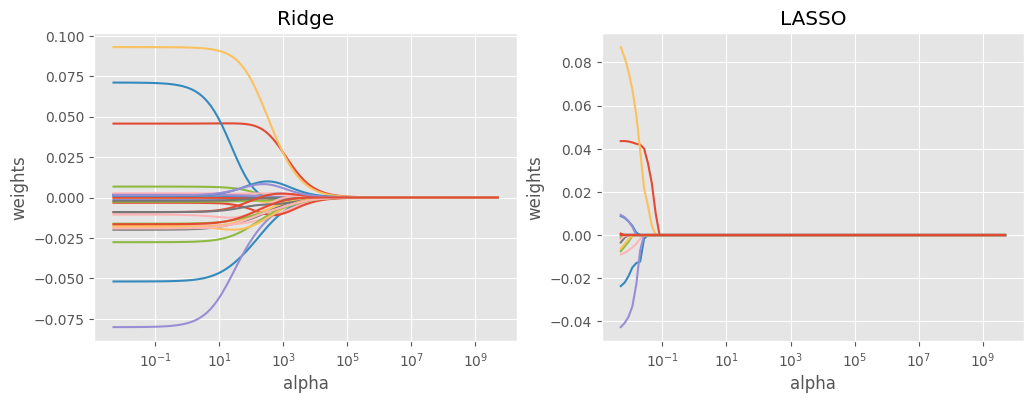

In [ ]:
# Ridge and Lasso coefficient paths
ridge = Ridge()
lasso = Lasso(max_iter = 10000)
ridge_coefs = []
lasso_coefs = []

for a in alphas:
    ridge.set_params(alpha=a)
    ridge.fit(X_train, y_train)
    ridge_coefs.append(ridge.coef_)

    lasso.set_params(alpha=a)
    lasso.fit(X_train, y_train)
    lasso_coefs.append(lasso.coef_)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)          # left
plt.plot(alphas, ridge_coefs)
plt.xscale('log')
plt.title('Ridge')
plt.xlabel('alpha')
plt.ylabel('weights')

plt.subplot(1, 2, 2)          # right
plt.plot(alphas, lasso_coefs)
plt.xscale('log')
plt.title('LASSO')
plt.xlabel('alpha')
plt.ylabel('weights')

plt.show()

The LASSO coefficient plot looks very different from the ridge plot. In the ridge plot, the coefficients shrank gradually and smoothly, only approaching zero at very large alpha values, and they never reached exactly zero. In the LASSO plot, the coefficients **drop to exactly zero one by one** as alpha increases, and once a coefficient reaches zero, the predictor is removed from the model.

Even at the smallest alpha tested (0.005), LASSO had already removed more than half of the predictors, keeping only 14 of the 29. As alpha increased, the less important variables, such as the team and day-of-week indicators, were removed first. By α = 0.02, only five predictors remained: incentive, targeted_productivity, smv, sewing and idle_men. The last two predictors to be removed were **incentive** (the top yellow line) and **targeted_productivity** (the red line), and by around α = 0.08 every coefficient was zero.

The order in which predictors are removed gives a useful ranking of importance. Variables that survive longest under a strong penalty are the ones that matter most for predicting productivity. This agrees with the ridge results, where incentive, targeted_productivity, sewing and smv also had the largest coefficients. The main difference is that ridge keeps every predictor with a small effect, while LASSO removes the weaker ones entirely, which gives a simpler model.

Note that the alpha values in the two plots are not directly comparable, because ridge and LASSO use different penalty formulas. What matters is the shape of the paths: gradual shrinkage for ridge, and shrinkage to exactly zero for LASSO.

In [ ]:
## Perform 10-fold cross-validation to choose the best alpha.

lassocv = LassoCV(alphas = None, cv = 10, max_iter = 100000)
lassocv.fit(X_train, y_train)

lasso.set_params(alpha=lassocv.alpha_)
lasso.fit(X_train, y_train)
mean_squared_error(y_test, lasso.predict(X_test))

0.017512729295002222

In [ ]:
# Some of the coefficients are now reduced to exactly zero.
pd.Series(lasso.coef_, index=X.columns)

,0
targeted_productivity,0.044789
smv,-0.036387
wip,-0.000000
over_time,-0.011884
incentive,0.095419
idle_time,0.003564
idle_men,-0.013334
no_of_style_change,-0.000729
no_of_workers,0.020489
sewing,-0.053674


Cross-validation was used to choose the best alpha for LASSO. LassoCV split the training data into 10 parts, tested a range of alpha values, and selected **α ≈ 0.00134**. Using this alpha, the LASSO model achieved a **test MSE of 0.01751 (RMSE ≈ 0.1323)**. This is very close to both ridge regression (test MSE = 0.01738) and ordinary linear regression (test MSE = 0.01730), so LASSO predicts productivity about as accurately as the other two methods.

The main difference is that LASSO set **6 of the 29 coefficients to exactly zero**: wip, quarter_Quarter3, day_Sunday, day_Thursday, day_Tuesday and team_2. These predictors were removed from the model, leaving 23. Most of them are day-of-week and quarter indicators, which were also not significant in the MLR model. This suggests that the timing of production has little effect on productivity once other factors are taken into account.

The most important predictors were the same as in ridge regression. **Financial incentive** was the strongest positive predictor (β ≈ +0.095), followed by targeted_productivity (β ≈ +0.045). The **sewing department** (β ≈ −0.054) and **smv** (β ≈ −0.036) were the strongest negative predictors. One notable difference is no_of_workers, which shrank from about +0.053 in ridge to +0.020 in LASSO. Because no_of_workers and sewing are strongly related (sewing teams have more workers), LASSO tends to keep one and shrink the other, whereas ridge shares the effect between them.

Overall, LASSO achieved practically the same accuracy as ridge while using fewer predictors, which makes it a simpler and easier model to interpret.

# **3.0 Discussion**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

kf = KFold(n_splits=5, shuffle=True, random_state=1)


def evaluate_5fold(model_name, X_data, y_data, fit_predict_fn, num_features):
  rmses, maes, adj_r2s = [], [], []
  for tr_idx, val_idx in kf.split(X_data):
    X_tr, X_val = X_data.iloc[tr_idx], X_data.iloc[val_idx]
    y_tr, y_val = y_data.iloc[tr_idx], y_data.iloc[val_idx]

    preds = fit_predict_fn(X_tr, y_tr, X_val)
    n_val = len(y_val)
    r2 = r2_score(y_val, preds)
    adj_r2 = 1 - (1 - r2) * (n_val - 1) / (n_val - num_features - 1)

    rmses.append(np.sqrt(mean_squared_error(y_val, preds)))
    maes.append(mean_absolute_error(y_val, preds))
    adj_r2s.append(adj_r2)
  return {
      'Model': model_name,
      'Predictors': num_features,
      '5-Fold RMSE': np.mean(rmses),
      '5-Fold MAE': np.mean(maes),
      '5-Fold Adj-R2': np.mean(adj_r2s),
  }


# 1. Full MLR (29 predictors)
res_mlr = evaluate_5fold(
    'Full Multiple Linear Regression',
    X,
    y,
    lambda X_tr, y_tr, X_val: LinearRegression().fit(X_tr, y_tr).predict(X_val),
    X.shape[1],
)

# 2. Mixed Stepwise (10 selected predictors from Section 2.2)
X_step = X[selected_features]
res_step = evaluate_5fold(
    'Mixed Stepwise Regression',
    X_step,
    y,
    lambda X_tr, y_tr, X_val: LinearRegression().fit(X_tr, y_tr).predict(X_val),
    len(selected_features),
)


# 3. Ridge Regression (alpha = 7.0874 from Section 2.3.1, scaled inside each fold)
def ridge_fn(X_tr, y_tr, X_val):
  sc = StandardScaler()
  X_tr_s = sc.fit_transform(X_tr)
  X_val_s = sc.transform(X_val)
  return Ridge(alpha=ridgecv.alpha_).fit(X_tr_s, y_tr).predict(X_val_s)


res_ridge = evaluate_5fold('Ridge Regression', X, y, ridge_fn, X.shape[1])


# 4. LASSO Regression (alpha = 0.00134 from Section 2.3.2, scaled inside each fold)
def lasso_fn(X_tr, y_tr, X_val):
  sc = StandardScaler()
  X_tr_s = sc.fit_transform(X_tr)
  X_val_s = sc.transform(X_val)
  return (
      Lasso(alpha=lassocv.alpha_, max_iter=100000)
      .fit(X_tr_s, y_tr)
      .predict(X_val_s)
  )


non_zero_lasso = int(np.sum(lasso.coef_ != 0))
res_lasso = evaluate_5fold('LASSO Regression', X, y, lasso_fn, non_zero_lasso)

comparison_df = pd.DataFrame([res_mlr, res_step, res_ridge, res_lasso])
display(comparison_df.round(4))

,Model,Predictors,5-Fold RMSE,5-Fold MAE,5-Fold Adj-R2
0,Full Multiple Linear Regression,29,0.1377,0.0978,0.2881
1,Mixed Stepwise Regression,10,0.1371,0.0959,0.3525
2,Ridge Regression,29,0.1376,0.0975,0.2884
3,LASSO Regression,23,0.1378,0.0968,0.3064


Based on identical 5-fold cross-validation splits (random_state=1), Mixed Forward–Backward Stepwise Regression achieved the best overall predictive performance, recording the lowest RMSE (0.1371), lowest MAE (0.0959) and highest Adjusted R² (0.3525). Full Multiple Linear Regression (MLR) and Ridge Regression produced very similar prediction errors, with RMSE values of 0.1377 and 0.1376 and MAE values of 0.0978 and 0.0975, respectively. However, their Adjusted R² values were lower at 0.2881 and 0.2884. LASSO Regression achieved a higher Adjusted R² of 0.3064 by eliminating six predictors, although its RMSE (0.1378) remained slightly higher than Mixed Stepwise Regression. Overall, Mixed Stepwise Regression provided the best balance between predictive performance and model simplicity.

All four models identified similar patterns among the important predictors of actual productivity. Financial incentives, targeted productivity and number of workers showed consistent positive relationships with actual productivity, while sewing department membership, Standard Minute Value (SMV), idle men and team_11 showed negative relationships. In contrast, variables such as quarter, day of the week, WIP, idle time and number of style changes were statistically insignificant in the full MLR model (p > 0.10). These variables were also excluded by Mixed Stepwise Regression, while LASSO reduced six coefficients to exactly zero, indicating that they contributed less to the respective models.

In terms of model complexity, the full MLR model recorded a high condition number of 9.32 × 10⁴, suggesting potential multicollinearity or numerical scaling issues among the predictors. Ridge Regression, with an optimised alpha value of 7.0874, applied L2 regularisation to reduce coefficient magnitudes, particularly for sewing and number of workers, but retained all 29 predictors. Meanwhile, LASSO Regression, with an optimised alpha value of 0.00134, applied L1 regularisation and reduced six coefficients (WIP, quarter_Quarter3, day_Sunday, day_Thursday, day_Tuesday and team_2) to zero, leaving 23 predictors. Mixed Stepwise Regression achieved the greatest reduction in model complexity by selecting only 10 statistically significant predictors from the original 29, representing a 65.5% reduction. Despite using fewer predictors, it outperformed the other three models across all reported cross-validation metrics, making it the most compact and effective model among the four approaches evaluated.

# **4.0 Conclusion**

Mixed Forward–Backward Stepwise Regression is recommended as the most suitable model for predicting garment employee productivity. Based on 5-fold cross-validation, it achieved the best predictive performance, with the lowest RMSE (0.1371), lowest MAE (0.0959) and highest Adjusted R² (0.3525). Its Adjusted R² was 0.0644 higher than Full Multiple Linear Regression (0.2881), while requiring only 10 predictors instead of 29. This makes the model more compact, easier to interpret and more practical for monitoring and application in garment production.

The findings also provide several practical considerations for factory management. Targeted productivity and financial incentives showed consistent positive relationships with actual productivity across the models. Therefore, management should consider setting realistic daily productivity targets and implementing structured financial incentive programmes to encourage employee performance. Meanwhile, sewing department membership and higher Standard Minute Value (SMV) were associated with lower productivity. Supervisors should consider allocating additional workflow time, technical support and resources during complex production runs, while investigating potential bottlenecks in teams with lower productivity, particularly team_11, team_6 and team_8 to team_10, where supported by the model results. In addition, the negative relationship between idle men and actual productivity highlights the importance of monitoring workforce utilisation and identifying causes of idle manpower to reduce potential production delays.

Despite its better performance, the selected model has limitations. Its predictive accuracy remains moderate, indicating that other factors not included in the dataset may also influence employee productivity. Furthermore, the regression results identify relationships rather than prove cause and effect. Future studies could include additional operational factors and test the model using data from other garment factories to improve its predictive accuracy and generalisability.